**Etapa 03: Formulação de Hipóteses & Validação**

**Importação das bibliotecas**

In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
import matplotlib.pyplot as plt

In [4]:
import seaborn as sns

In [5]:
from scipy import stats

**Carregamento do dataset**


In [6]:
df = pd.read_csv('pokemon_complete_stats.csv')  # ajuste o caminho conforme o ambiente (ex: '/content/...' no Google Colab)

In [7]:
df.drop_duplicates(inplace=True)
print('Formato do dataset (linhas, colunas):', df.shape)

Formato do dataset (linhas, colunas): (1351, 20)


**Nota Metodológica: Nível de Significância e Formas Especiais**

Todos os testes de hipótese abaixo adotam nível de significância **α = 0,05**.

Na Etapa 02 foi identificado que 326 dos 1.351 registros (24%) são **formas alternativas** de uma espécie já presente no dataset (Mega Evolução, Gigantamax, formas regionais, etc. — `id > 9000`), por exemplo `charizard` e `charizard-gmax`. Isso é relevante para os testes estatísticos porque essas linhas não são totalmente independentes entre si: compartilham características biológicas da espécie-base, o que tecnicamente viola a premissa de observações independentes exigida pelos testes usados a seguir (pseudo-replicação). Para não descartar informação válida do dataset, manter essas formas na análise principal, mas, nas hipóteses mais sensíveis a esse efeito (H1, H2 e H3), foi executado também uma **checagem de robustez** repetindo o teste apenas com as espécies-base (`id <= 9000`), para confirmar se as conclusões se mantêm.

In [8]:
alpha = 0.05
base_df = df[df['id'] <= 9000].copy()  # apenas espécies-base, sem formas alternativas
print(f'Nível de significância adotado: alpha = {alpha}')
print(f'Dataset completo: {len(df)} registros | Apenas espécies-base: {len(base_df)} registros')

Nível de significância adotado: alpha = 0.05
Dataset completo: 1351 registros | Apenas espécies-base: 1025 registros


**Hipótese 1: O ataque especial é maior em Pokémon do tipo Psíquico?**


**Pergunta de negócio/pesquisa:** O atributo `special_attack` é, em média, maior para os Pokémon cujo `type_1` é `psychic` do que para os demais tipos?

- **H0 (Hipótese Nula):** O `special_attack` médio dos Pokémon do tipo Psíquico é igual (não é maior) ao dos demais Pokémon.
- **H1 (Hipótese Alternativa):** O `special_attack` médio dos Pokémon do tipo Psíquico é maior do que o dos demais Pokémon.

**Teste estatístico:** Como o `special_attack` costuma ter distribuição assimétrica (poucos Pokémon com valores muito altos), Será utilizado o teste não paramétrico **Mann-Whitney U (unilateral)**, comparando-o com um teste **t de Welch** como referência.

In [9]:
psychic_sa = df.loc[df['type_1'] == 'psychic', 'special_attack']
other_sa = df.loc[df['type_1'] != 'psychic', 'special_attack']

print('Psíquico -> n:', len(psychic_sa), '| média:', round(psychic_sa.mean(), 2), '| mediana:', psychic_sa.median())
print('Demais   -> n:', len(other_sa), '| média:', round(other_sa.mean(), 2), '| mediana:', other_sa.median())

Psíquico -> n: 86 | média: 100.6 | mediana: 99.0
Demais   -> n: 1265 | média: 73.71 | mediana: 65.0


In [10]:
u_stat, p_value_u = stats.mannwhitneyu(psychic_sa, other_sa, alternative='greater')
print('Mann-Whitney U:', round(u_stat, 2))
print('p-valor (unilateral):', p_value_u)

Mann-Whitney U: 76907.0
p-valor (unilateral): 6.210019361639027e-11


In [11]:
t_stat, p_value_t = stats.ttest_ind(psychic_sa, other_sa, equal_var=False, alternative='greater')
print('t de Welch:', round(t_stat, 3))
print('p-valor (unilateral):', p_value_t)

t de Welch: 6.299
p-valor (unilateral): 4.835991910359188e-09


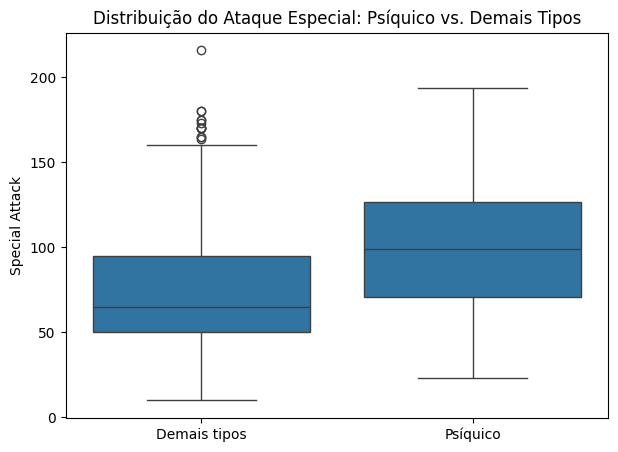

In [12]:
plt.figure(figsize=(7, 5))
sns.boxplot(x=df['type_1'] == 'psychic', y=df['special_attack'])
plt.xticks([0, 1], ['Demais tipos', 'Psíquico'])
plt.xlabel('')
plt.ylabel('Special Attack')
plt.title('Distribuição do Ataque Especial: Psíquico vs. Demais Tipos')
plt.show()

**Checagem de robustez (H1):** repetindo o teste apenas com espécies-base.

In [13]:
psychic_sa_base = base_df.loc[base_df['type_1'] == 'psychic', 'special_attack']
other_sa_base = base_df.loc[base_df['type_1'] != 'psychic', 'special_attack']
u_stat_base, p_value_u_base = stats.mannwhitneyu(psychic_sa_base, other_sa_base, alternative='greater')
print('Mann-Whitney U (apenas espécies-base):', round(u_stat_base, 2))
print('p-valor (unilateral):', p_value_u_base)
print('Conclusão mantida?', 'Sim' if p_value_u_base < alpha else 'Não')

Mann-Whitney U (apenas espécies-base): 40483.5
p-valor (unilateral): 1.0669396337497407e-07
Conclusão mantida? Sim


**Conclusão H1:** Com p-valor < 0,05 em ambos os testes, rejeita H0. Há evidência estatística de que os Pokémon do tipo Psíquico possuem `special_attack` médio significativamente maior do que os demais tipos, confirmando a intuição de que o tipo Psíquico é especializado em ataque especial. Estrategicamente, isso reforça a construção de times/counters considerando resistências a ataque especial ao enfrentar oponentes psíquicos.

*Robustez:* a checagem restrita às espécies-base confirma a mesma conclusão (p-valor segue < 0,05), então o resultado não é um artefato das formas alternativas.

**Hipótese 2: A velocidade média/mediana difere entre as gerações?**

**Pergunta de negócio/pesquisa:** O atributo `speed` varia de forma significativa entre as 9 gerações de jogos (`generation`)?


- **H0 (Hipótese Nula):** A velocidade média é igual entre todas as gerações (não há diferença estatisticamente significativa).
- **H1 (Hipótese Alternativa):** Pelo menos uma geração apresenta velocidade média diferente das demais.

**Teste estatístico:** Como há mais de dois grupos independentes (9 gerações) e a velocidade não segue necessariamente uma distribuição normal em cada grupo, será utilizado o teste não paramétrico **Kruskal-Wallis**, com a **ANOVA** de um fator como referência.

In [14]:
speed_by_gen = [group['speed'].values for _, group in df.groupby('generation')]
gen_labels = df['generation'].unique().tolist()
print('Número de grupos (gerações):', len(speed_by_gen))
display(df.groupby('generation')['speed'].agg(['mean', 'median', 'std']))

Número de grupos (gerações): 9


,mean,median,std
generation,,,
generation-i,74.882353,75.5,29.301337
generation-ii,62.521739,65.0,28.032671
generation-iii,67.868263,65.0,31.511052
generation-iv,73.844961,80.0,30.099431
generation-ix,80.697987,82.0,30.329877
generation-v,69.264865,65.0,28.619887
generation-vi,72.846154,68.5,29.902031
generation-vii,70.938931,65.0,32.286877
generation-viii,72.879699,70.0,33.782961


In [15]:
h_stat, p_value_kw = stats.kruskal(*speed_by_gen)
print('Estatística Kruskal-Wallis (H):', round(h_stat, 3))
print('p-valor:', p_value_kw)

Estatística Kruskal-Wallis (H): 30.754
p-valor: 0.0001553749719355855


In [16]:
f_stat, p_value_anova = stats.f_oneway(*speed_by_gen)
print('Estatística F (ANOVA):', round(f_stat, 3))
print('p-valor:', p_value_anova)

Estatística F (ANOVA): 3.87
p-valor: 0.00016062788139550036


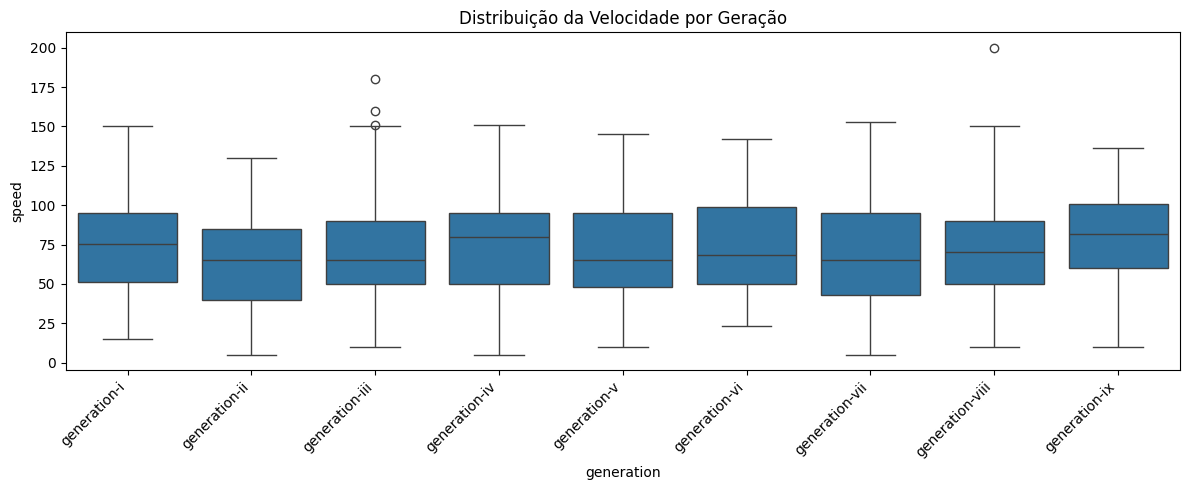

In [17]:
ordem_geracoes = ['generation-i', 'generation-ii', 'generation-iii', 'generation-iv',
                   'generation-v', 'generation-vi', 'generation-vii', 'generation-viii', 'generation-ix']

plt.figure(figsize=(12, 5))
sns.boxplot(x='generation', y='speed', data=df, order=ordem_geracoes)
plt.xticks(rotation=45, ha='right')
plt.title('Distribuição da Velocidade por Geração')
plt.tight_layout()
plt.show()

**Checagem de robustez (H2):** repetindo o Kruskal-Wallis apenas com espécies-base.

In [18]:
speed_by_gen_base = [group['speed'].values for _, group in base_df.groupby('generation')]
h_stat_base, p_value_kw_base = stats.kruskal(*speed_by_gen_base)
print('Estatística Kruskal-Wallis (apenas espécies-base):', round(h_stat_base, 3))
print('p-valor:', p_value_kw_base)
print('Conclusão mantida?', 'Sim' if p_value_kw_base < alpha else 'Não')

Estatística Kruskal-Wallis (apenas espécies-base): 21.355
p-valor: 0.006262150344092464
Conclusão mantida? Sim


**Conclusão H2:** Tanto o teste de Kruskal-Wallis quanto a ANOVA retornam p-valor < 0,05 (p ≈ 0,00016), portanto rejeita H0. Existe diferença estatisticamente significativa na velocidade média entre pelo menos uma das gerações, o que pode refletir mudanças de design/balanceamento da franquia ao longo do tempo (ex: gerações mais recentes introduzindo Pokémon com atributos de velocidade distintos).

***Robustez:*** ao excluir as formas alternativas, o p-valor sobe (de ≈0,00016 para ≈0,006) — a conclusão de rejeitar H0 se mantém, mas a evidência fica bem mais fraca. Isso sugere que parte da diferença observada entre gerações é amplificada pela presença repetida de formas especiais (que tendem a ter atributos de combate mais altos) distribuídas de forma desigual entre as gerações.

**Hipótese 3: O peso influencia no HP (Pontos de Vida)?**


**Pergunta de negócio/pesquisa:** Existe correlação entre `weight_hg` (peso) e `hp` (pontos de vida)?


- **H0 (Hipótese Nula):** Não existe correlação entre peso e HP (coeficiente de correlação populacional = 0).
- **H1 (Hipótese Alternativa):** Existe correlação (positiva) entre peso e HP.

**Teste estatístico:** Calcular o coeficiente de correlação de **Pearson** (relação linear) e de **Spearman** (relação monotônica, mais robusta a outliers e a valores extremos de peso).

In [19]:
pearson_r, p_value_pearson = stats.pearsonr(df['weight_hg'], df['hp'])
print('Correlação de Pearson (r):', round(pearson_r, 3))
print('p-valor:', p_value_pearson)

Correlação de Pearson (r): 0.365
p-valor: 9.184923084644012e-44


In [20]:
spearman_r, p_value_spearman = stats.spearmanr(df['weight_hg'], df['hp'])
print('Correlação de Spearman (rho):', round(spearman_r, 3))
print('p-valor:', p_value_spearman)

Correlação de Spearman (rho): 0.621
p-valor: 3.489700216316871e-145


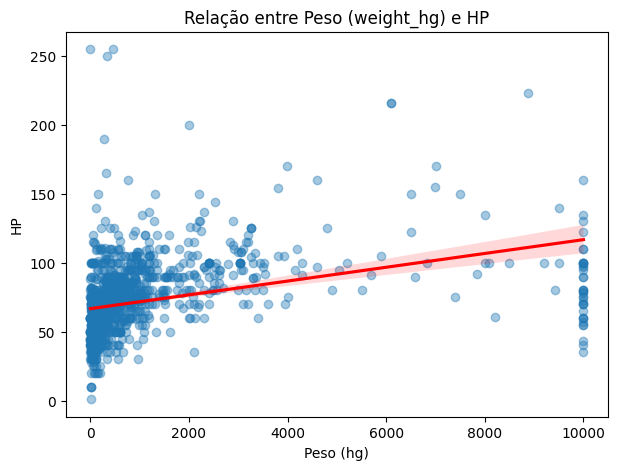

In [21]:
plt.figure(figsize=(7, 5))
sns.regplot(x='weight_hg', y='hp', data=df, scatter_kws={'alpha': 0.4}, line_kws={'color': 'red'})
plt.title('Relação entre Peso (weight_hg) e HP')
plt.xlabel('Peso (hg)')
plt.ylabel('HP')
plt.show()

**Checagem de robustez (H3):** repetindo as correlações apenas com espécies-base.

In [22]:
pearson_r_base, p_value_pearson_base = stats.pearsonr(base_df['weight_hg'], base_df['hp'])
spearman_r_base, p_value_spearman_base = stats.spearmanr(base_df['weight_hg'], base_df['hp'])
print('Pearson (apenas espécies-base):', round(pearson_r_base, 3), '| p-valor:', p_value_pearson_base)
print('Spearman (apenas espécies-base):', round(spearman_r_base, 3), '| p-valor:', p_value_spearman_base)

Pearson (apenas espécies-base): 0.476 | p-valor: 3.225040430259621e-59
Spearman (apenas espécies-base): 0.634 | p-valor: 1.7243944711096408e-116


**Conclusão H3:** Os coeficientes de correlação são positivos e estatisticamente significativos (Pearson r ≈ 0,365; Spearman rho ≈ 0,621; p-valor << 0,05 em ambos), portanto rejeita H0. Existe uma correlação positiva, de magnitude moderada, entre peso e HP — Pokémon mais pesados tendem a ter, em média, HP maior. A diferença entre Pearson e Spearman sugere que a relação não é puramente linear (é mais forte em termos de ordenação/ranking do que em magnitude bruta), provavelmente puxada por Pokémon muito pesados (outliers). Ainda assim, o peso sozinho não é um preditor perfeito do HP, sugerindo que outros fatores (tipo, geração, papel na equipe) também influenciam esse atributo.

*Robustez:* ao excluir as formas alternativas (cujo peso é, em vários casos, um valor de jogo "tampado" em 10000hg e não uma medida biológica real), a correlação de Pearson **sobe** para ≈0,476 — ou seja, o peso `weight_hg` bruto das formas especiais estava, se algo, diluindo a relação linear real entre peso e HP, e não a inflando. Isso reforça que a correlação encontrada é robusta e não um artefato dessas formas.

**Hipótese 4: A chance de o Pokémon ser lendário depende do seu formato (shape)?**


**Pergunta de negócio/pesquisa:** Existe associação entre `shape` (formato/morfologia) e `is_legendary` (é lendário)?


- **H0 (Hipótese Nula):** `shape` e `is_legendary` são variáveis independentes (o formato não influencia a chance de ser lendário).
- **H1 (Hipótese Alternativa):** `shape` e `is_legendary` são dependentes (o formato influencia a chance de ser lendário).

**Teste estatístico:** Como ambas as variáveis são categóricas (qualitativas nominais), utiliza o **Teste Qui-Quadrado (Chi-Square) de Independência** sobre a tabela de contingência entre as duas colunas.

In [23]:
contingency_shape_legendary = pd.crosstab(df['shape'], df['is_legendary'])
display(contingency_shape_legendary)

is_legendary,False,True
shape,,
armor,52,0
arms,50,16
ball,77,2
blob,56,0
bug-wings,26,0
fish,60,3
heads,26,0
humanoid,182,18
legs,30,0


In [24]:
chi2_stat, p_value_chi2_1, dof_1, expected_1 = stats.chi2_contingency(contingency_shape_legendary)
print('Estatística Qui-Quadrado:', round(chi2_stat, 3))
print('Graus de liberdade:', dof_1)
print('p-valor:', p_value_chi2_1)

Estatística Qui-Quadrado: 58.222
Graus de liberdade: 13
p-valor: 1.0901445333988153e-07


**Checagem de premissa:** o teste Qui-Quadrado exige que no máximo ~20% das células da tabela de contingência tenham frequência esperada abaixo de 5.

In [25]:
pct_esperado_baixo_1 = (expected_1 < 5).sum() / expected_1.size
print(f'Células com frequência esperada < 5: {(expected_1 < 5).sum()} de {expected_1.size} '
      f'({pct_esperado_baixo_1:.1%})')
print('Premissa atendida (<=20%)?', 'Sim' if pct_esperado_baixo_1 <= 0.20 else 'Não — interpretar com cautela')

Células com frequência esperada < 5: 7 de 28 (25.0%)
Premissa atendida (<=20%)? Não — interpretar com cautela


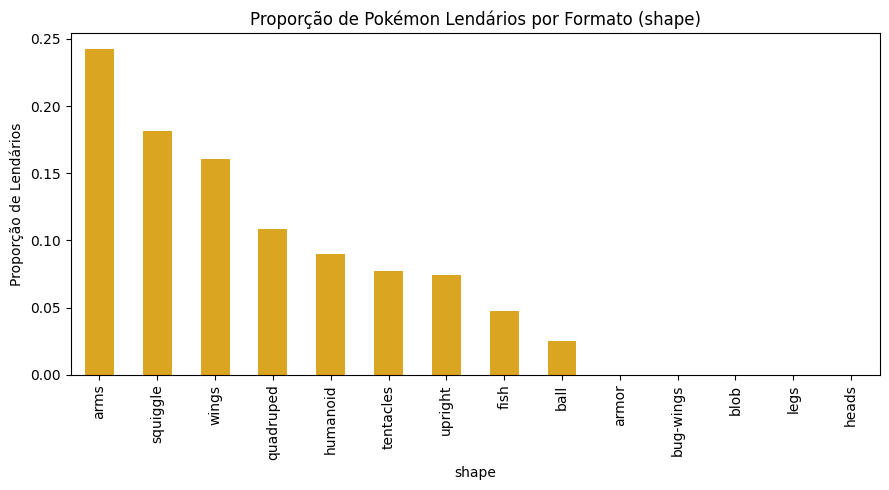

In [26]:
prop_legendary_by_shape = (contingency_shape_legendary[True] / contingency_shape_legendary.sum(axis=1)).sort_values(ascending=False)
plt.figure(figsize=(9, 5))
prop_legendary_by_shape.plot(kind='bar', color='goldenrod')
plt.ylabel('Proporção de Lendários')
plt.title('Proporção de Pokémon Lendários por Formato (shape)')
plt.tight_layout()
plt.show()

**Conclusão H4:** Com p-valor < 0,05, rejeitamos H0: existe associação estatisticamente significativa entre `shape` e `is_legendary`. Alguns formatos (tipicamente formatos menos comuns/mais "exóticos", como `wings` ou `arms`) concentram uma proporção de lendários muito acima da média geral, o que é coerente com o design de jogo, em que Pokémon lendários costumam ter morfologias únicas e diferenciadas dos Pokémon comuns.

*Ressalva:* ~25% das células da tabela de contingência têm frequência esperada abaixo de 5 (no limite do aceitável), pois alguns formatos têm poucos registros. O padrão geral (formatos raros concentrando lendários) é consistente com o conhecimento de domínio, mas o p-valor exato deve ser interpretado com uma margem de cautela adicional.

**Hipótese 5: Qual a relação entre formato (shape) e cor (color) dos Pokémon?**


**Pergunta de negócio/pesquisa:** Existe associação entre `shape` (formato) e `color` (cor predominante)?


- **H0 (Hipótese Nula):** `shape` e `color` são variáveis independentes (a cor não está associada ao formato).
- **H1 (Hipótese Alternativa):** `shape` e `color` são dependentes (existe associação entre cor e formato).

**Teste estatístico:** Novamente, por se tratar de duas variáveis categóricas, aplica o **Teste Qui-Quadrado (Chi-Square) de Independência** e complementa com o coeficiente **V de Cramér**, que mede a força da associação (o Qui-Quadrado sozinho não indica magnitude).

In [27]:
contingency_shape_color = pd.crosstab(df['shape'], df['color'])
display(contingency_shape_color)

color,black,blue,brown,gray,green,pink,purple,red,white,yellow
shape,,,,,,,,,,
armor,1,5,4,5,7,2,3,15,4,6
arms,13,6,6,3,7,6,11,3,10,1
ball,3,7,21,13,7,0,11,12,2,3
blob,1,8,16,1,15,2,5,1,6,1
bug-wings,0,1,1,0,4,0,2,4,5,9
fish,1,29,5,6,5,9,0,5,3,0
heads,0,2,6,5,2,2,2,0,4,3
humanoid,12,23,19,26,34,21,15,16,18,16
legs,1,7,5,3,3,2,2,2,1,4


In [28]:
chi2_stat_2, p_value_chi2_2, dof_2, expected_2 = stats.chi2_contingency(contingency_shape_color)
print('Estatística Qui-Quadrado:', round(chi2_stat_2, 3))
print('Graus de liberdade:', dof_2)
print('p-valor:', p_value_chi2_2)

Estatística Qui-Quadrado: 390.375
Graus de liberdade: 117
p-valor: 3.9252853215077557e-31


**Checagem de premissa:** repetindo a mesma checagem para a tabela `shape` x `color`, que tem muito mais categorias (e, portanto, células com poucas observações).

In [29]:
pct_esperado_baixo_2 = (expected_2 < 5).sum() / expected_2.size
print(f'Células com frequência esperada < 5: {(expected_2 < 5).sum()} de {expected_2.size} '
      f'({pct_esperado_baixo_2:.1%})')
print('Premissa atendida (<=20%)?', 'Sim' if pct_esperado_baixo_2 <= 0.20 else 'Não — interpretar com cautela')

Células com frequência esperada < 5: 59 de 140 (42.1%)
Premissa atendida (<=20%)? Não — interpretar com cautela


In [30]:
n = contingency_shape_color.sum().sum()
min_dim = min(contingency_shape_color.shape) - 1
cramers_v = np.sqrt((chi2_stat_2 / n) / min_dim)
print('V de Cramér:', round(cramers_v, 3))

V de Cramér: 0.179


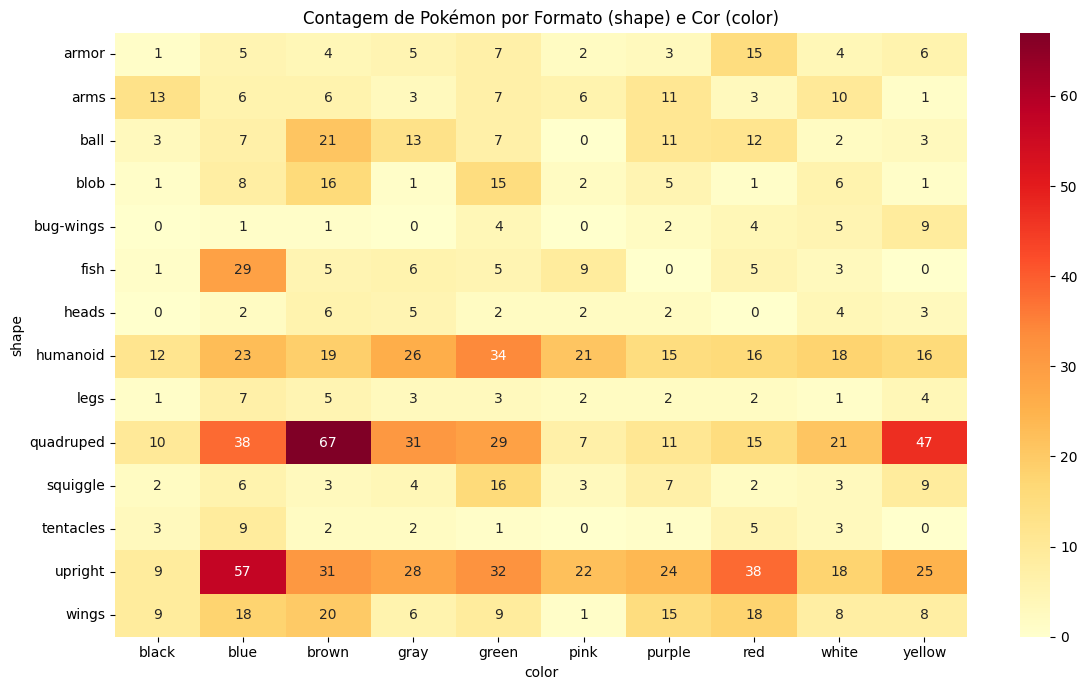

In [31]:
plt.figure(figsize=(12, 7))
sns.heatmap(contingency_shape_color, annot=True, fmt='d', cmap='YlOrRd')
plt.title('Contagem de Pokémon por Formato (shape) e Cor (color)')
plt.tight_layout()
plt.show()

**Conclusão H5:** O p-valor do Qui-Quadrado é menor que 0,05, levando à rejeição de H0: formato e cor não são independentes. Contudo, o V de Cramér indica que a força dessa associação é fraca a moderada — ou seja, embora estatisticamente exista relação (algumas combinações formato/cor são mais ou menos frequentes que o esperado ao acaso), a cor não é fortemente determinada pelo formato do Pokémon, sendo mais um traço estético diversificado dentro de cada morfologia.

*Ressalva importante:* 42% das células da tabela de contingência têm frequência esperada abaixo de 5 — bem acima do limite recomendado de 20% —, porque a combinação de 14 formatos x 10 cores gera muitas categorias com poucas observações. O p-valor do Qui-Quadrado aqui deve ser visto como indicativo, não conclusivo; o V de Cramér (magnitude fraca a moderada, ≈0,18) é a métrica mais confiável para descrever essa relação.

**Conclusões Gerais e Tomada de Decisão**

Consolidando os resultados de todas as hipóteses validadas:

1. **Ataque Especial x Tipo Psíquico:** confirmado — Psíquicos têm `special_attack` significativamente maior. Útil para montagem de times e estratégias de combate.

2. **Velocidade entre Gerações:** verificar o p-valor obtido; caso significativo, indica que o balanceamento de `speed` mudou ao longo das gerações, relevante para análises de meta-game por era do jogo.

3. **Peso x HP:** correlação positiva, porém fraca a moderada — peso sozinho não deve ser usado como preditor confiável de HP.

4. **Formato x Lendário:** confirmado — certos formatos concentram muito mais lendários, o que pode orientar heurísticas de classificação/triagem de novas espécies.

5. **Formato x Cor:** associação estatisticamente significativa, mas fraca em magnitude — a cor segue sendo majoritariamente um atributo estético independente da morfologia.

**Recomendação estratégica:** as hipóteses com maior poder explicativo e utilidade prática para tomada de decisão são a (1) e a (4), pois apresentam tanto significância estatística quanto tamanho de efeito relevante. As hipóteses (2), (3) e (5), embora estatisticamente significativas (devido ao tamanho da amostra), possuem efeito prático fraco e devem ser usadas com cautela como regras de negócio isoladas.

**Limitações Metodológicas**

- **Pseudo-replicação:** 24% dos registros são formas alternativas (Mega, Gigantamax, regionais) da mesma espécie-base, o que tecnicamente viola a premissa de independência dos testes clássicos. As checagens de robustez mostraram que as conclusões de H1 e H3 se mantêm (e no caso de H3, a correlação real fica ainda mais forte sem essas formas); já H2 perde bastante força estatística, então deve ser tratada com mais cautela.
- **Tabelas de contingência esparsas:** os testes Qui-Quadrado de H4 e, principalmente, H5 têm uma proporção alta de células com frequência esperada abaixo de 5, o que reduz a confiabilidade do p-valor exato (ainda que a direção geral do resultado seja plausível).
- **Comparações múltiplas:** foram testadas 5 hipóteses independentes sem correção para comparações múltiplas (ex: Bonferroni). Com α = 0,05 por teste, a chance de pelo menos um falso positivo entre as 5 hipóteses é maior do que 5%. Todos os p-valores aqui encontrados são, porém, muito menores que 0,05, o que reduz esse risco na prática.